Clone dataset dari GitHub

In [14]:
!git clone https://github.com/pratikkayal/PlantDoc-Dataset.git

fatal: destination path 'PlantDoc-Dataset' already exists and is not an empty directory.


Periksa struktur folder

In [15]:
import os

dataset_path = "/content/PlantDoc-Dataset"

print("Dataset berhasil dimuat:", os.path.exists(dataset_path))
print("Isi folder dataset:", os.listdir(dataset_path))

Dataset berhasil dimuat: True
Isi folder dataset: ['LICENSE.txt', 'train', 'PlantDoc_Examples.png', 'README.md', '.git', 'test']


Periksa struktur dataset

In [16]:

from pathlib import Path

dataset_path = Path("/content/PlantDoc-Dataset")
ekstensi_gambar = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "test"]:
    folder_split = dataset_path / split

    print(f"\n===== DATASET {split.upper()} =====")

    if not folder_split.exists():
        print("Folder tidak ditemukan!")
        continue

    kelas = sorted(
        folder for folder in folder_split.iterdir()
        if folder.is_dir()
    )

    total_gambar = 0

    print("Jumlah kelas:", len(kelas))

    for folder_kelas in kelas:
        jumlah = sum(
            1 for file in folder_kelas.rglob("*")
            if file.is_file()
            and file.suffix.lower() in ekstensi_gambar
        )

        total_gambar += jumlah
        print(f"{folder_kelas.name}: {jumlah} gambar")

    print("Total gambar:", total_gambar)



===== DATASET TRAIN =====
Jumlah kelas: 28
Apple Scab Leaf: 83 gambar
Apple leaf: 82 gambar
Apple rust leaf: 79 gambar
Bell_pepper leaf: 53 gambar
Bell_pepper leaf spot: 62 gambar
Blueberry leaf: 106 gambar
Cherry leaf: 47 gambar
Corn Gray leaf spot: 64 gambar
Corn leaf blight: 180 gambar
Corn rust leaf: 106 gambar
Peach leaf: 103 gambar
Potato leaf early blight: 109 gambar
Potato leaf late blight: 97 gambar
Raspberry leaf: 112 gambar
Soyabean leaf: 57 gambar
Squash Powdery mildew leaf: 124 gambar
Strawberry leaf: 88 gambar
Tomato Early blight leaf: 79 gambar
Tomato Septoria leaf spot: 140 gambar
Tomato leaf: 55 gambar
Tomato leaf bacterial spot: 101 gambar
Tomato leaf late blight: 101 gambar
Tomato leaf mosaic virus: 44 gambar
Tomato leaf yellow virus: 70 gambar
Tomato mold leaf: 85 gambar
Tomato two spotted spider mites leaf: 2 gambar
grape leaf: 57 gambar
grape leaf black rot: 56 gambar
Total gambar: 2342

===== DATASET TEST =====
Jumlah kelas: 27
Apple Scab Leaf: 10 gambar
Apple l

Mengunduh dataset kembali untuk GPU

In [17]:
import os

dataset_path = "/content/PlantDoc-Dataset"

if os.path.exists(dataset_path):
    print("Dataset masih tersedia, tidak perlu unduh ulang.")
else:
    print("Dataset tidak ditemukan, perlu unduh ulang.")

Dataset masih tersedia, tidak perlu unduh ulang.


In [18]:
!git clone https://github.com/pratikkayal/PlantDoc-Dataset.git

fatal: destination path 'PlantDoc-Dataset' already exists and is not an empty directory.


Periksa GPU dan dataset

In [19]:

import os
import torch

dataset_path = "/content/PlantDoc-Dataset"

print("GPU tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))

print("Dataset tersedia:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Folder dataset:", os.listdir(dataset_path))


GPU tersedia: True
Nama GPU: Tesla T4
Dataset tersedia: True
Folder dataset: ['LICENSE.txt', 'train', 'PlantDoc_Examples.png', 'README.md', '.git', 'test']


Periksa perbedaan kelas train dan test

In [20]:

from pathlib import Path

dataset_path = Path("/content/PlantDoc-Dataset")

train_path = dataset_path / "train"
test_path = dataset_path / "test"

train_classes = {
    folder.name for folder in train_path.iterdir()
    if folder.is_dir()
}

test_classes = {
    folder.name for folder in test_path.iterdir()
    if folder.is_dir()
}

print("Jumlah kelas train:", len(train_classes))
print("Jumlah kelas test:", len(test_classes))

print("\nKelas yang ada di train tetapi tidak ada di test:")
print(sorted(train_classes - test_classes))

print("\nKelas yang ada di test tetapi tidak ada di train:")
print(sorted(test_classes - train_classes))

print("\nJumlah kelas yang sama:", len(train_classes & test_classes))


Jumlah kelas train: 28
Jumlah kelas test: 27

Kelas yang ada di train tetapi tidak ada di test:
['Tomato two spotted spider mites leaf']

Kelas yang ada di test tetapi tidak ada di train:
[]

Jumlah kelas yang sama: 27


Menyiapkan dataset untuk eksperimen

In [21]:

from pathlib import Path

dataset_path = Path("/content/PlantDoc-Dataset")
train_path = dataset_path / "train"
test_path = dataset_path / "test"

ekstensi_gambar = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

train_classes = {
    folder.name for folder in train_path.iterdir()
    if folder.is_dir()
}
test_classes = {
    folder.name for folder in test_path.iterdir()
    if folder.is_dir()
}

# Gunakan kelas yang tersedia pada kedua split
classes = sorted(train_classes & test_classes)

print("Jumlah kelas yang digunakan:", len(classes))
print("\nDaftar kelas:")

for i, nama_kelas in enumerate(classes):
    print(f"{i}: {nama_kelas}")

total_train = sum(
    1 for nama in classes
    for file in (train_path / nama).rglob("*")
    if file.is_file() and file.suffix.lower() in ekstensi_gambar
)

total_test = sum(
    1 for nama in classes
    for file in (test_path / nama).rglob("*")
    if file.is_file() and file.suffix.lower() in ekstensi_gambar
)

print("\nTotal gambar train:", total_train)
print("Total gambar test:", total_test)


Jumlah kelas yang digunakan: 27

Daftar kelas:
0: Apple Scab Leaf
1: Apple leaf
2: Apple rust leaf
3: Bell_pepper leaf
4: Bell_pepper leaf spot
5: Blueberry leaf
6: Cherry leaf
7: Corn Gray leaf spot
8: Corn leaf blight
9: Corn rust leaf
10: Peach leaf
11: Potato leaf early blight
12: Potato leaf late blight
13: Raspberry leaf
14: Soyabean leaf
15: Squash Powdery mildew leaf
16: Strawberry leaf
17: Tomato Early blight leaf
18: Tomato Septoria leaf spot
19: Tomato leaf
20: Tomato leaf bacterial spot
21: Tomato leaf late blight
22: Tomato leaf mosaic virus
23: Tomato leaf yellow virus
24: Tomato mold leaf
25: grape leaf
26: grape leaf black rot

Total gambar train: 2340
Total gambar test: 236


Menyiapkan preprocessing gambar

In [22]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Ukuran gambar dan konfigurasi eksperimen
IMAGE_SIZE = 224
BATCH_SIZE = 16
SEED = 42

# Normalisasi sesuai standar ImageNet
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Transformasi gambar untuk training
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Transformasi untuk validasi dan pengujian
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Preprocessing berhasil disiapkan.")
print("Ukuran gambar:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Seed:", SEED)


Preprocessing berhasil disiapkan.
Ukuran gambar: 224 x 224
Batch size: 16
Seed: 42


Membagi data training dan validasi

In [23]:

from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
import numpy as np

# Baca dataset training tanpa transformasi terlebih dahulu
full_train_dataset = ImageFolder(
    root=str(train_path),
    transform=None
)

# Pilih hanya 27 kelas yang tersedia pada train dan test
selected_indices = [
    i for i, (_, label) in enumerate(full_train_dataset.samples)
    if full_train_dataset.classes[label] in classes
]

selected_labels = np.array([
    full_train_dataset.targets[i]
    for i in selected_indices
])

# Pembagian 80% train dan 20% validation secara stratified
train_indices, val_indices = train_test_split(
    selected_indices,
    test_size=0.2,
    random_state=SEED,
    stratify=selected_labels
)

# Dataset training dengan augmentasi
train_dataset_all = ImageFolder(
    root=str(train_path),
    transform=train_transform
)

# Dataset validasi tanpa augmentasi
val_dataset_all = ImageFolder(
    root=str(train_path),
    transform=eval_transform
)

train_dataset = Subset(train_dataset_all, train_indices)
val_dataset = Subset(val_dataset_all, val_indices)

print("Jumlah data latih:", len(train_dataset))
print("Jumlah data validasi:", len(val_dataset))
print("Jumlah kelas:", len(classes))




# Dataset test hanya menggunakan 27 kelas yang disepakati
test_dataset_all = ImageFolder(
    root=str(test_path),
    transform=eval_transform
)

test_indices = [
    i for i, (_, label) in enumerate(test_dataset_all.samples)
    if test_dataset_all.classes[label] in classes
]

test_dataset = Subset(test_dataset_all, test_indices)

# DataLoader untuk setiap tahap
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Jumlah data test:", len(test_dataset))
print("Jumlah batch train:", len(train_loader))
print("Jumlah batch validasi:", len(val_loader))
print("Jumlah batch test:", len(test_loader))


Jumlah data latih: 1872
Jumlah data validasi: 468
Jumlah kelas: 27
Jumlah data test: 236
Jumlah batch train: 117
Jumlah batch validasi: 30
Jumlah batch test: 15


Memastikan label kelas konsisten

In [24]:

from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
import numpy as np

# Pemetaan kelas yang sama untuk seluruh eksperimen
class_to_idx = {name: i for i, name in enumerate(classes)}

class RemappedDataset(Dataset):
    def __init__(self, base_dataset, indices, class_to_idx):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image_index = self.indices[index]
        image, old_label = self.base_dataset[image_index]

        class_name = self.base_dataset.classes[old_label]
        new_label = self.class_to_idx[class_name]

        return image, new_label

# Dataset train dan validasi
train_base = ImageFolder(str(train_path), transform=train_transform)
val_base = ImageFolder(str(train_path), transform=eval_transform)

valid_train_indices = [
    i for i, (_, label) in enumerate(train_base.samples)
    if train_base.classes[label] in class_to_idx
]

labels = [
    class_to_idx[train_base.classes[train_base.samples[i][1]]]
    for i in valid_train_indices
]

train_indices, val_indices = train_test_split(
    valid_train_indices,
    test_size=0.2,
    random_state=SEED,
    stratify=labels
)

train_dataset = RemappedDataset(
    train_base, train_indices, class_to_idx
)
val_dataset = RemappedDataset(
    val_base, val_indices, class_to_idx
)

# Dataset test
test_base = ImageFolder(str(test_path), transform=eval_transform)

test_indices = [
    i for i, (_, label) in enumerate(test_base.samples)
    if test_base.classes[label] in class_to_idx
]

test_dataset = RemappedDataset(
    test_base, test_indices, class_to_idx
)

# DataLoader
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=2, pin_memory=True
)

print("Pemetaan label konsisten:", len(class_to_idx), "kelas")
print("Data latih:", len(train_dataset))
print("Data validasi:", len(val_dataset))
print("Data test:", len(test_dataset))


Pemetaan label konsisten: 27 kelas
Data latih: 1872
Data validasi: 468
Data test: 236


Membuat model VGG16

In [25]:

import torch
import torch.nn as nn
from torchvision import models

# Gunakan GPU jika tersedia
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Perangkat:", device)

# Muat VGG16 pretrained ImageNet
weights = models.VGG16_Weights.DEFAULT
model_vgg16 = models.vgg16(weights=weights)

# Ganti lapisan klasifikasi terakhir untuk 27 kelas
num_features = model_vgg16.classifier[6].in_features
model_vgg16.classifier[6] = nn.Linear(num_features, len(classes))

# Pindahkan model ke GPU
model_vgg16 = model_vgg16.to(device)

# Fungsi loss dan optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model_vgg16.parameters(),
    lr=0.0001
)

print("Model VGG16 berhasil dibuat.")
print("Jumlah kelas output:", len(classes))
print("Jumlah parameter:",
      sum(p.numel() for p in model_vgg16.parameters()))


Perangkat: cuda
Model VGG16 berhasil dibuat.
Jumlah kelas output: 27
Jumlah parameter: 134371163


menjalankan pelatihan VGG16

In [26]:

import copy
import torch

EPOCHS = 5

best_val_loss = float("inf")
best_vgg16_state = None
history_vgg16 = []

for epoch in range(EPOCHS):
    # ===== TRAINING =====
    model_vgg16.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_vgg16(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ===== VALIDATION =====
    model_vgg16.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_vgg16(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history_vgg16.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    # Simpan bobot dengan validation loss terbaik
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_vgg16_state = copy.deepcopy(model_vgg16.state_dict())

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

# Kembalikan bobot terbaik berdasarkan validation loss
model_vgg16.load_state_dict(best_vgg16_state)

# Simpan checkpoint ke penyimpanan sementara Colab
torch.save(
    model_vgg16.state_dict(),
    "/content/vgg16_plantdoc_best.pth"
)

print("\nPelatihan VGG16 selesai.")
print("Validation loss terbaik:", round(best_val_loss, 4))


Epoch [1/5] | Train Loss: 2.6778 | Train Acc: 0.2174 | Val Loss: 2.2322 | Val Acc: 0.3504
Epoch [2/5] | Train Loss: 1.9470 | Train Acc: 0.3857 | Val Loss: 1.9043 | Val Acc: 0.4487
Epoch [3/5] | Train Loss: 1.5336 | Train Acc: 0.4957 | Val Loss: 1.5975 | Val Acc: 0.5214
Epoch [4/5] | Train Loss: 1.1839 | Train Acc: 0.6063 | Val Loss: 1.5778 | Val Acc: 0.5406
Epoch [5/5] | Train Loss: 1.0020 | Train Acc: 0.6720 | Val Loss: 1.3757 | Val Acc: 0.5705

Pelatihan VGG16 selesai.
Validation loss terbaik: 1.3757


Evaluasi VGG16

In [27]:

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

model_vgg16.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_vgg16(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

precision_vgg16 = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall_vgg16 = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1_vgg16 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("Hasil evaluasi VGG16 pada data test")
print(f"Precision : {precision_vgg16:.4f}")
print(f"Recall    : {recall_vgg16:.4f}")
print(f"F1-score  : {f1_vgg16:.4f}")


Hasil evaluasi VGG16 pada data test
Precision : 0.5989
Recall    : 0.5566
F1-score  : 0.5205


Membangun model ResNet18

In [28]:

from torchvision import models
import torch.nn as nn

# Muat ResNet18 pretrained
model_resnet18 = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Ganti lapisan klasifikasi menjadi 27 kelas
num_features = model_resnet18.fc.in_features
model_resnet18.fc = nn.Linear(num_features, len(classes))

# Pindahkan ke GPU
model_resnet18 = model_resnet18.to(device)

# Loss dan optimizer
criterion_resnet18 = nn.CrossEntropyLoss()
optimizer_resnet18 = torch.optim.Adam(
    model_resnet18.parameters(),
    lr=0.0001
)

print("Model ResNet18 berhasil dibuat.")
print("Perangkat:", device)
print("Jumlah kelas output:", len(classes))
print(
    "Jumlah parameter:",
    sum(p.numel() for p in model_resnet18.parameters())
)


Model ResNet18 berhasil dibuat.
Perangkat: cuda
Jumlah kelas output: 27
Jumlah parameter: 11190363


menjalankan pelatihan ResNet18

In [29]:

import copy
import torch

EPOCHS = 5

best_val_loss_resnet18 = float("inf")
best_resnet18_state = None
history_resnet18 = []

for epoch in range(EPOCHS):
    # Training
    model_resnet18.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet18.zero_grad()

        outputs = model_resnet18(images)
        loss = criterion_resnet18(outputs, labels)

        loss.backward()
        optimizer_resnet18.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validasi
    model_resnet18.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_resnet18(images)
            loss = criterion_resnet18(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history_resnet18.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    if val_loss < best_val_loss_resnet18:
        best_val_loss_resnet18 = val_loss
        best_resnet18_state = copy.deepcopy(
            model_resnet18.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

model_resnet18.load_state_dict(best_resnet18_state)

torch.save(
    model_resnet18.state_dict(),
    "/content/resnet18_plantdoc_best.pth"
)

print("\nPelatihan ResNet18 selesai.")
print(
    "Validation loss terbaik:",
    round(best_val_loss_resnet18, 4)
)


Epoch [1/5] | Train Loss: 2.2446 | Train Acc: 0.3510 | Val Loss: 1.5182 | Val Acc: 0.5684
Epoch [2/5] | Train Loss: 1.1283 | Train Acc: 0.6971 | Val Loss: 1.2310 | Val Acc: 0.6325
Epoch [3/5] | Train Loss: 0.6905 | Train Acc: 0.8312 | Val Loss: 1.2434 | Val Acc: 0.6068
Epoch [4/5] | Train Loss: 0.4054 | Train Acc: 0.9290 | Val Loss: 1.1749 | Val Acc: 0.6603
Epoch [5/5] | Train Loss: 0.2666 | Train Acc: 0.9503 | Val Loss: 1.2640 | Val Acc: 0.6197

Pelatihan ResNet18 selesai.
Validation loss terbaik: 1.1749


Evaluasi ResNet18

In [30]:

from sklearn.metrics import precision_score, recall_score, f1_score

model_resnet18.eval()

y_true_resnet18 = []
y_pred_resnet18 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_resnet18(images)
        predictions = outputs.argmax(dim=1)

        y_true_resnet18.extend(labels.numpy())
        y_pred_resnet18.extend(predictions.cpu().numpy())

precision_resnet18 = precision_score(
    y_true_resnet18,
    y_pred_resnet18,
    average="macro",
    zero_division=0
)

recall_resnet18 = recall_score(
    y_true_resnet18,
    y_pred_resnet18,
    average="macro",
    zero_division=0
)

f1_resnet18 = f1_score(
    y_true_resnet18,
    y_pred_resnet18,
    average="macro",
    zero_division=0
)

print("Hasil evaluasi ResNet18 pada data test")
print(f"Precision : {precision_resnet18:.4f}")
print(f"Recall    : {recall_resnet18:.4f}")
print(f"F1-score  : {f1_resnet18:.4f}")


Hasil evaluasi ResNet18 pada data test
Precision : 0.6660
Recall    : 0.6393
F1-score  : 0.6239


Membuat model ResNet34

In [31]:

import torch
import torch.nn as nn
from torchvision import models

# Muat ResNet34 dengan bobot pretrained ImageNet
model_resnet34 = models.resnet34(
    weights=models.ResNet34_Weights.DEFAULT
)

# Ganti lapisan output menjadi 27 kelas
num_features = model_resnet34.fc.in_features
model_resnet34.fc = nn.Linear(num_features, len(classes))

# Pindahkan model ke GPU
model_resnet34 = model_resnet34.to(device)

# Siapkan loss dan optimizer khusus ResNet34
criterion_resnet34 = nn.CrossEntropyLoss()

optimizer_resnet34 = torch.optim.Adam(
    model_resnet34.parameters(),
    lr=0.0001
)

print("Model ResNet34 berhasil dibuat.")
print("Perangkat:", device)
print("Jumlah kelas output:", len(classes))
print(
    "Jumlah parameter:",
    sum(p.numel() for p in model_resnet34.parameters())
)


Model ResNet34 berhasil dibuat.
Perangkat: cuda
Jumlah kelas output: 27
Jumlah parameter: 21298523


Menjalankan pelatihan ResNet34

In [32]:

import copy
import torch

EPOCHS = 5

best_val_loss_resnet34 = float("inf")
best_resnet34_state = None
history_resnet34 = []

for epoch in range(EPOCHS):
    # Training
    model_resnet34.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet34.zero_grad()

        outputs = model_resnet34(images)
        loss = criterion_resnet34(outputs, labels)

        loss.backward()
        optimizer_resnet34.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    model_resnet34.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_resnet34(images)
            loss = criterion_resnet34(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history_resnet34.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    if val_loss < best_val_loss_resnet34:
        best_val_loss_resnet34 = val_loss
        best_resnet34_state = copy.deepcopy(
            model_resnet34.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

model_resnet34.load_state_dict(best_resnet34_state)

torch.save(
    model_resnet34.state_dict(),
    "/content/resnet34_plantdoc_best.pth"
)

print("\nPelatihan ResNet34 selesai.")
print(
    "Validation loss terbaik:",
    round(best_val_loss_resnet34, 4)
)


Epoch [1/5] | Train Loss: 2.1386 | Train Acc: 0.3851 | Val Loss: 1.4303 | Val Acc: 0.5470
Epoch [2/5] | Train Loss: 1.0363 | Train Acc: 0.7067 | Val Loss: 1.2616 | Val Acc: 0.6303
Epoch [3/5] | Train Loss: 0.5956 | Train Acc: 0.8488 | Val Loss: 1.2755 | Val Acc: 0.5769
Epoch [4/5] | Train Loss: 0.3695 | Train Acc: 0.9033 | Val Loss: 1.3052 | Val Acc: 0.6026
Epoch [5/5] | Train Loss: 0.2777 | Train Acc: 0.9263 | Val Loss: 1.4035 | Val Acc: 0.6004

Pelatihan ResNet34 selesai.
Validation loss terbaik: 1.2616


Evaluasi ResNet34

In [33]:

from sklearn.metrics import precision_score, recall_score, f1_score

model_resnet34.eval()

y_true_resnet34 = []
y_pred_resnet34 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_resnet34(images)
        predictions = outputs.argmax(dim=1)

        y_true_resnet34.extend(labels.numpy())
        y_pred_resnet34.extend(predictions.cpu().numpy())

precision_resnet34 = precision_score(
    y_true_resnet34,
    y_pred_resnet34,
    average="macro",
    zero_division=0
)

recall_resnet34 = recall_score(
    y_true_resnet34,
    y_pred_resnet34,
    average="macro",
    zero_division=0
)

f1_resnet34 = f1_score(
    y_true_resnet34,
    y_pred_resnet34,
    average="macro",
    zero_division=0
)

print("Hasil evaluasi ResNet34 pada data test")
print(f"Precision : {precision_resnet34:.4f}")
print(f"Recall    : {recall_resnet34:.4f}")
print(f"F1-score  : {f1_resnet34:.4f}")


Hasil evaluasi ResNet34 pada data test
Precision : 0.5973
Recall    : 0.5590
F1-score  : 0.5578


Membuat model EfficientNet-B0

In [34]:

import torch
import torch.nn as nn
from torchvision import models

# Muat EfficientNet-B0 pretrained ImageNet
model_efficientnet_b0 = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

# Ganti lapisan klasifikasi menjadi 27 kelas
num_features = model_efficientnet_b0.classifier[1].in_features
model_efficientnet_b0.classifier[1] = nn.Linear(
    num_features, len(classes)
)

# Pindahkan model ke GPU
model_efficientnet_b0 = model_efficientnet_b0.to(device)

# Loss dan optimizer
criterion_b0 = nn.CrossEntropyLoss()

optimizer_b0 = torch.optim.Adam(
    model_efficientnet_b0.parameters(),
    lr=0.0001
)

print("Model EfficientNet-B0 berhasil dibuat.")
print("Perangkat:", device)
print("Jumlah kelas output:", len(classes))
print(
    "Jumlah parameter:",
    sum(p.numel() for p in model_efficientnet_b0.parameters())
)


Model EfficientNet-B0 berhasil dibuat.
Perangkat: cuda
Jumlah kelas output: 27
Jumlah parameter: 4042135


Menjalankan pelatihan EfficientNet-B0

In [35]:

import copy
import torch

EPOCHS = 5

best_val_loss_b0 = float("inf")
best_b0_state = None
history_b0 = []

for epoch in range(EPOCHS):
    # Training
    model_efficientnet_b0.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_b0.zero_grad()

        outputs = model_efficientnet_b0(images)
        loss = criterion_b0(outputs, labels)

        loss.backward()
        optimizer_b0.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    model_efficientnet_b0.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_efficientnet_b0(images)
            loss = criterion_b0(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history_b0.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    if val_loss < best_val_loss_b0:
        best_val_loss_b0 = val_loss
        best_b0_state = copy.deepcopy(
            model_efficientnet_b0.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

model_efficientnet_b0.load_state_dict(best_b0_state)

torch.save(
    model_efficientnet_b0.state_dict(),
    "/content/efficientnet_b0_plantdoc_best.pth"
)

print("\nPelatihan EfficientNet-B0 selesai.")
print("Validation loss terbaik:", round(best_val_loss_b0, 4))


Epoch [1/5] | Train Loss: 2.9215 | Train Acc: 0.2238 | Val Loss: 2.3848 | Val Acc: 0.4209
Epoch [2/5] | Train Loss: 2.0248 | Train Acc: 0.4829 | Val Loss: 1.6963 | Val Acc: 0.5449
Epoch [3/5] | Train Loss: 1.4892 | Train Acc: 0.5876 | Val Loss: 1.3540 | Val Acc: 0.5962
Epoch [4/5] | Train Loss: 1.0982 | Train Acc: 0.7067 | Val Loss: 1.2218 | Val Acc: 0.6239
Epoch [5/5] | Train Loss: 0.8627 | Train Acc: 0.7601 | Val Loss: 1.1257 | Val Acc: 0.6581

Pelatihan EfficientNet-B0 selesai.
Validation loss terbaik: 1.1257


Evaluasi EfficientNet-B0

In [36]:

from sklearn.metrics import precision_score, recall_score, f1_score
import torch

model_efficientnet_b0.eval()

y_true_b0 = []
y_pred_b0 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_efficientnet_b0(images)
        predictions = outputs.argmax(dim=1)

        y_true_b0.extend(labels.cpu().numpy())
        y_pred_b0.extend(predictions.cpu().numpy())

precision_b0 = precision_score(
    y_true_b0, y_pred_b0,
    average="macro", zero_division=0
)

recall_b0 = recall_score(
    y_true_b0, y_pred_b0,
    average="macro", zero_division=0
)

f1_b0 = f1_score(
    y_true_b0, y_pred_b0,
    average="macro", zero_division=0
)

print("Hasil evaluasi EfficientNet-B0 pada data test")
print(f"Precision : {precision_b0:.4f}")
print(f"Recall    : {recall_b0:.4f}")
print(f"F1-score  : {f1_b0:.4f}")


Hasil evaluasi EfficientNet-B0 pada data test
Precision : 0.6579
Recall    : 0.6363
F1-score  : 0.6190


Membuat model EfficientNet-B1

In [37]:

import torch
import torch.nn as nn
from torchvision import models

# Membuat model EfficientNet-B1 dengan pretrained weights
weights_b1 = models.EfficientNet_B1_Weights.DEFAULT
model_efficientnet_b1 = models.efficientnet_b1(weights=weights_b1)

# Mengganti classifier untuk 27 kelas penyakit tanaman
num_features_b1 = model_efficientnet_b1.classifier[1].in_features
model_efficientnet_b1.classifier[1] = nn.Linear(
    num_features_b1, len(classes)
)

# Memindahkan model ke GPU
model_efficientnet_b1 = model_efficientnet_b1.to(device)

# Loss function dan optimizer
criterion_b1 = nn.CrossEntropyLoss()
optimizer_b1 = torch.optim.Adam(
    model_efficientnet_b1.parameters(),
    lr=0.0001
)

print("Model EfficientNet-B1 berhasil dibuat.")
print("Perangkat:", device)
print("Jumlah kelas output:", len(classes))
print(
    "Jumlah parameter:",
    sum(p.numel() for p in model_efficientnet_b1.parameters())
)


Model EfficientNet-B1 berhasil dibuat.
Perangkat: cuda
Jumlah kelas output: 27
Jumlah parameter: 6547771


Melatih EfficientNet-B1 selama 5 epoch

In [38]:

import copy
import torch

EPOCHS = 5

best_val_loss_b1 = float("inf")
best_b1_state = None
history_b1 = []

for epoch in range(EPOCHS):
    # Training
    model_efficientnet_b1.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_b1.zero_grad()

        outputs = model_efficientnet_b1(images)
        loss = criterion_b1(outputs, labels)

        loss.backward()
        optimizer_b1.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    model_efficientnet_b1.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_efficientnet_b1(images)
            loss = criterion_b1(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history_b1.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    if val_loss < best_val_loss_b1:
        best_val_loss_b1 = val_loss
        best_b1_state = copy.deepcopy(
            model_efficientnet_b1.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

model_efficientnet_b1.load_state_dict(best_b1_state)

torch.save(
    model_efficientnet_b1.state_dict(),
    "/content/efficientnet_b1_plantdoc_best.pth"
)

print("\nPelatihan EfficientNet-B1 selesai.")
print("Validation loss terbaik:", round(best_val_loss_b1, 4))


Epoch [1/5] | Train Loss: 3.0869 | Train Acc: 0.2035 | Val Loss: 2.6191 | Val Acc: 0.3739
Epoch [2/5] | Train Loss: 2.1591 | Train Acc: 0.4241 | Val Loss: 1.6957 | Val Acc: 0.4872
Epoch [3/5] | Train Loss: 1.5325 | Train Acc: 0.5694 | Val Loss: 1.3219 | Val Acc: 0.6132
Epoch [4/5] | Train Loss: 1.1804 | Train Acc: 0.6757 | Val Loss: 1.1399 | Val Acc: 0.6453
Epoch [5/5] | Train Loss: 0.9599 | Train Acc: 0.7206 | Val Loss: 1.0321 | Val Acc: 0.6667

Pelatihan EfficientNet-B1 selesai.
Validation loss terbaik: 1.0321


Hitung Precision, Recall, dan F1-score EfficientNet-B1

In [39]:

from sklearn.metrics import precision_score, recall_score, f1_score
import torch

model_efficientnet_b1.eval()

y_true_b1 = []
y_pred_b1 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_efficientnet_b1(images)
        predictions = outputs.argmax(dim=1)

        y_true_b1.extend(labels.cpu().numpy())
        y_pred_b1.extend(predictions.cpu().numpy())

precision_b1 = precision_score(
    y_true_b1, y_pred_b1,
    average="macro", zero_division=0
)

recall_b1 = recall_score(
    y_true_b1, y_pred_b1,
    average="macro", zero_division=0
)

f1_b1 = f1_score(
    y_true_b1, y_pred_b1,
    average="macro", zero_division=0
)

print("Hasil evaluasi EfficientNet-B1 pada data test")
print(f"Precision : {precision_b1:.4f}")
print(f"Recall    : {recall_b1:.4f}")
print(f"F1-score  : {f1_b1:.4f}")


Hasil evaluasi EfficientNet-B1 pada data test
Precision : 0.6779
Recall    : 0.6572
F1-score  : 0.6478


Membuat tabel perbandingan hasil

In [40]:

import pandas as pd
from IPython.display import display

# Menggabungkan hasil evaluasi kelima model
hasil = pd.DataFrame([
    {
        "Metode": "VGG16",
        "Precision": precision_vgg16,
        "Recall": recall_vgg16,
        "F1-score": f1_vgg16
    },
    {
        "Metode": "ResNet18",
        "Precision": precision_resnet18,
        "Recall": recall_resnet18,
        "F1-score": f1_resnet18
    },
    {
        "Metode": "ResNet34",
        "Precision": precision_resnet34,
        "Recall": recall_resnet34,
        "F1-score": f1_resnet34
    },
    {
        "Metode": "EfficientNet-B0",
        "Precision": precision_b0,
        "Recall": recall_b0,
        "F1-score": f1_b0
    },
    {
        "Metode": "EfficientNet-B1",
        "Precision": precision_b1,
        "Recall": recall_b1,
        "F1-score": f1_b1
    }
])

# Mengurutkan berdasarkan F1-score tertinggi
hasil = hasil.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

# Menampilkan tabel dengan empat angka desimal
display(
    hasil.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

# Menyimpan tabel ke CSV
hasil.to_csv(
    "/content/hasil_perbandingan_model.csv",
    index=False,
    float_format="%.4f"
)

print("Tabel berhasil disimpan ke hasil_perbandingan_model.csv")


,Metode,Precision,Recall,F1-score
0,EfficientNet-B1,0.6779,0.6572,0.6478
1,ResNet18,0.6660,0.6393,0.6239
2,EfficientNet-B0,0.6579,0.6363,0.6190
3,ResNet34,0.5973,0.5590,0.5578
4,VGG16,0.5989,0.5566,0.5205


Tabel berhasil disimpan ke hasil_perbandingan_model.csv


Unduh tabel untuk laporan

In [41]:

from google.colab import files

files.download("/content/hasil_perbandingan_model.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

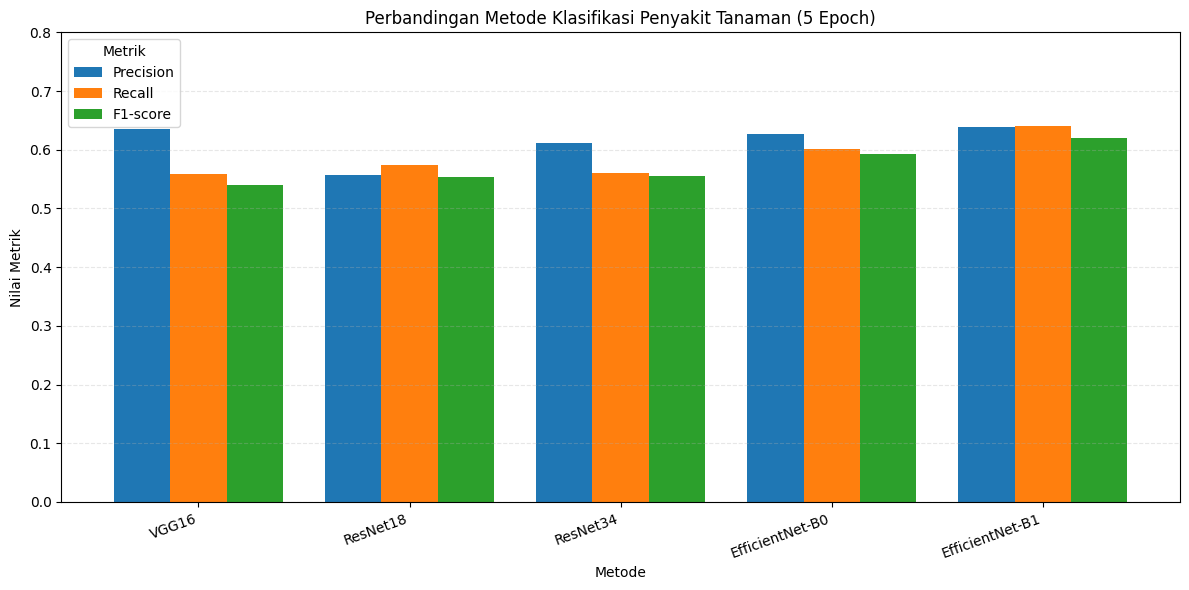

Chart disimpan sebagai chart_perbandingan_5_epoch.png


In [60]:

import pandas as pd
import matplotlib.pyplot as plt

# Hasil evaluasi eksperimen 5 epoch
hasil_5_epoch = pd.DataFrame({
    "Metode": [
        "VGG16",
        "ResNet18",
        "ResNet34",
        "EfficientNet-B0",
        "EfficientNet-B1"
    ],
    "Precision": [0.6360, 0.5577, 0.6121, 0.6268, 0.6379],
    "Recall":    [0.5583, 0.5732, 0.5604, 0.6020, 0.6412],
    "F1-score":  [0.5402, 0.5543, 0.5554, 0.5930, 0.6205]
})

# Chart perbandingan metrik
ax = hasil_5_epoch.set_index("Metode").plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Perbandingan Metode Klasifikasi Penyakit Tanaman (5 Epoch)")
ax.set_xlabel("Metode")
ax.set_ylabel("Nilai Metrik")
ax.set_ylim(0, 0.8)
ax.legend(title="Metrik")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

# Simpan gambar untuk laporan
plt.savefig("chart_perbandingan_5_epoch.png", dpi=300,
            bbox_inches="tight")
plt.show()

print("Chart disimpan sebagai chart_perbandingan_5_epoch.png")


In [63]:
print("Variabel classes tersedia:", "classes" in globals())

if "classes" in globals():
    print("Jumlah kelas:", len(classes))
    print("Contoh nama kelas:", classes[:5])

print("Dataset test tersedia:", "test_dataset" in globals())
print("Jenis dataset:", type(test_dataset).__name__)

Variabel classes tersedia: True
Jumlah kelas: 27
Contoh nama kelas: ['Apple Scab Leaf', 'Apple leaf', 'Apple rust leaf', 'Bell_pepper leaf', 'Bell_pepper leaf spot']
Dataset test tersedia: True
Jenis dataset: PlantDocSubDataset


Muat kembali model EfficientNet-B1

In [64]:
import torch
import torch.nn as nn
from torchvision import models

# Gunakan daftar kelas yang sudah dibuat sebelumnya
num_classes = len(classes)

# Buat arsitektur EfficientNet-B1
model_b1 = models.efficientnet_b1(weights=None)

# Sesuaikan layer output dengan jumlah kelas
num_features = model_b1.classifier[1].in_features
model_b1.classifier[1] = nn.Linear(
    num_features, num_classes
)

# Muat checkpoint hasil training 5 epoch
checkpoint_path = "/content/efficientnet_b1_plantdoc_best.pth"

state_dict = torch.load(
    checkpoint_path,
    map_location=device
)

model_b1.load_state_dict(state_dict)
model_b1 = model_b1.to(device)
model_b1.eval()

print("EfficientNet-B1 berhasil dimuat.")
print("Jumlah kelas:", num_classes)
print("Perangkat:", device)

EfficientNet-B1 berhasil dimuat.
Jumlah kelas: 27
Perangkat: cuda


Mengambil delapan gambar dan menampilkan prediksi

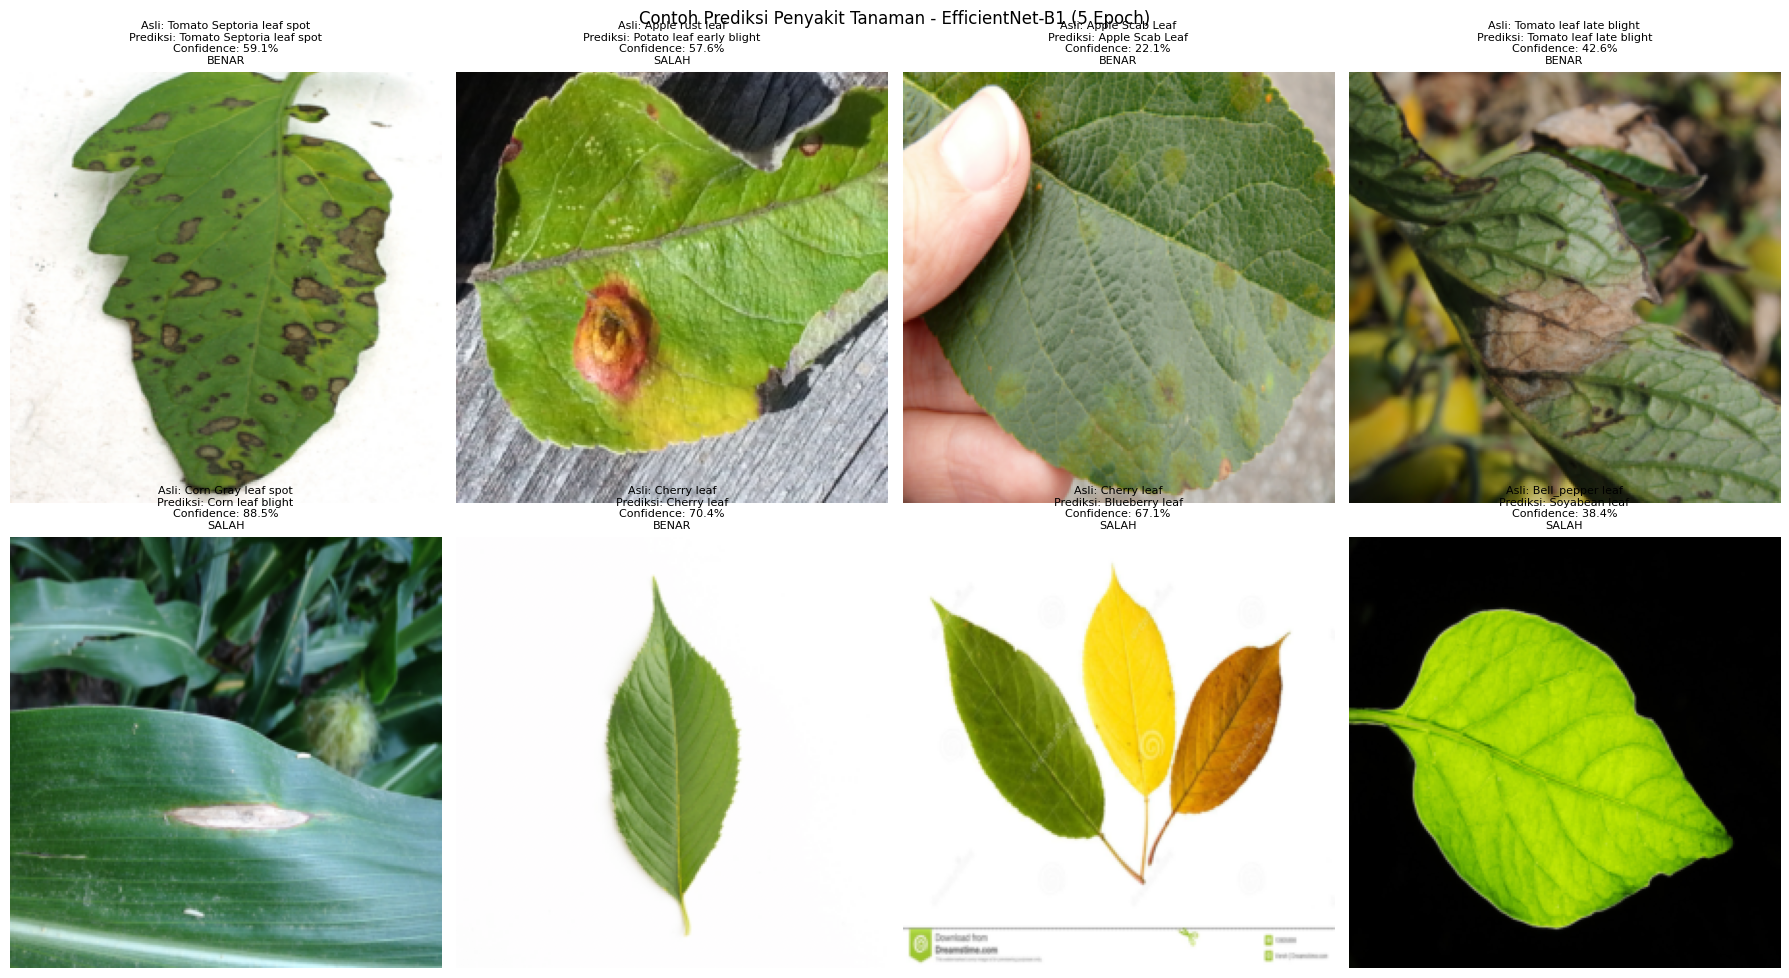

,Index Gambar,Label Asli,Prediksi,Confidence (%),Status
0,163,Tomato Septoria leaf spot,Tomato Septoria leaf spot,59.14,Benar
1,28,Apple rust leaf,Potato leaf early blight,57.60,Salah
2,6,Apple Scab Leaf,Apple Scab Leaf,22.09,Benar
3,189,Tomato leaf late blight,Tomato leaf late blight,42.57,Benar
4,70,Corn Gray leaf spot,Corn leaf blight,88.49,Salah
5,62,Cherry leaf,Cherry leaf,70.39,Benar
6,57,Cherry leaf,Blueberry leaf,67.06,Salah
7,35,Bell_pepper leaf,Soyabean leaf,38.36,Salah


Gambar dan tabel prediksi berhasil dibuat.


In [67]:

import random
import torch
import matplotlib.pyplot as plt
import pandas as pd

model_b1.eval()

# Gunakan daftar kelas yang dibuat saat training
nama_kelas = classes

# Pilih 8 sampel acak dari test dataset
random.seed(42)
jumlah_sampel = min(8, len(test_dataset))
sample_indices = random.sample(
    range(len(test_dataset)), jumlah_sampel
)

hasil_prediksi = []

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

with torch.no_grad():
    for posisi, idx in enumerate(sample_indices):
        image_tensor, label_asli = test_dataset[idx]

        output = model_b1(image_tensor.unsqueeze(0).to(device))
        probabilities = torch.softmax(output, dim=1)
        confidence, pred_idx = probabilities.max(dim=1)

        # Gunakan daftar kelas, bukan test_dataset.classes
        nama_asli = nama_kelas[int(label_asli)]
        nama_prediksi = nama_kelas[pred_idx.item()]
        benar = int(label_asli) == pred_idx.item()

        # Kembalikan normalisasi untuk menampilkan gambar
        gambar = (image_tensor.cpu() * std + mean)
        gambar = gambar.clamp(0, 1).permute(1, 2, 0).numpy()

        axes[posisi].imshow(gambar)
        axes[posisi].set_title(
            f"Asli: {nama_asli}\n"
            f"Prediksi: {nama_prediksi}\n"
            f"Confidence: {confidence.item()*100:.1f}%\n"
            f"{'BENAR' if benar else 'SALAH'}",
            fontsize=8
        )
        axes[posisi].axis("off")

        hasil_prediksi.append({
            "Index Gambar": idx,
            "Label Asli": nama_asli,
            "Prediksi": nama_prediksi,
            "Confidence (%)": round(confidence.item()*100, 2),
            "Status": "Benar" if benar else "Salah"
        })

# Sembunyikan panel yang tidak terpakai
for i in range(jumlah_sampel, len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "Contoh Prediksi Penyakit Tanaman - EfficientNet-B1 (5 Epoch)"
)
plt.tight_layout()
plt.savefig(
    "contoh_prediksi_efficientnet_b1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

tabel_prediksi = pd.DataFrame(hasil_prediksi)
display(tabel_prediksi)

tabel_prediksi.to_csv(
    "contoh_hasil_prediksi_efficientnet_b1.csv",
    index=False
)

print("Gambar dan tabel prediksi berhasil dibuat.")
